# PID Control: Implementation and Evaluation

This notebook introduces and evaluates a Proportional–Integral–Derivative (PID) controller.

The implementation uses a simple first-order dynamic system to study:

- Proportional (P) control
- Integral (I) control
- Derivative (D) control
- Combined PID control
- Tracking error and control response
- The influence of controller gains

In [1]:
# 1-18D — Environment and Library Setup

import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Environment setup completed.")

NumPy version: 2.4.6
Environment setup completed.


## Control Objective

The objective is to make a system follow a desired reference value.

For this experiment:

- Desired reference: 10
- Initial system output: 0
- Simulation duration: 10 seconds
- The controller calculates a control input based on the tracking error.

The tracking error is defined as:

\[
e(t) = r(t) - y(t)
\]

where:

- \(r(t)\) is the reference value.
- \(y(t)\) is the actual system output.

In [2]:
# 2-18D — Simulation Parameters and Reference

dt = 0.01
simulation_time = 10.0

time = np.arange(0, simulation_time, dt)

reference = 10.0
initial_output = 0.0

print("Simulation duration:", simulation_time, "seconds")
print("Time step:", dt, "seconds")
print("Reference value:", reference)

Simulation duration: 10.0 seconds
Time step: 0.01 seconds
Reference value: 10.0


## First-Order System Model

A simple first-order system is used to evaluate the controller.

The system is represented as:

\[
\frac{dy}{dt} = \frac{K u - y}{\tau}
\]

where:

- \(y\) is the system output.
- \(u\) is the control input.
- \(K\) is the system gain.
- \(\tau\) is the system time constant.

The model represents a simplified dynamic system and is not a complete vehicle model.

In [3]:
# 3-18D — First-Order System Parameters

system_gain = 1.0
time_constant = 1.0

print("System gain:", system_gain)
print("Time constant:", time_constant)

System gain: 1.0
Time constant: 1.0


## PID Controller

The PID control law is:

\[
u(t) =
K_p e(t)
+
K_i \int_0^t e(\tau)d\tau
+
K_d \frac{de(t)}{dt}
\]

The three terms have different functions:

- **Proportional term:** Responds to the current error.
- **Integral term:** Accumulates past error and helps reduce steady-state error.
- **Derivative term:** Responds to the rate of change of error and can reduce rapid changes.

The controller is implemented in discrete time.

In [4]:
# 4-18D — PID Controller Implementation

class PIDController:
    def __init__(self, kp, ki, kd, dt, output_limits=None):
        self.kp = kp
        self.ki = ki
        self.kd = kd
        self.dt = dt

        self.previous_error = 0.0
        self.integral = 0.0

        self.output_limits = output_limits

    def reset(self):
        self.previous_error = 0.0
        self.integral = 0.0

    def compute(self, error):
        proportional = self.kp * error

        self.integral += error * self.dt
        integral = self.ki * self.integral

        derivative_error = (
            error - self.previous_error
        ) / self.dt

        derivative = self.kd * derivative_error

        control_input = proportional + integral + derivative

        if self.output_limits is not None:
            minimum, maximum = self.output_limits
            control_input = np.clip(
                control_input,
                minimum,
                maximum
            )

        self.previous_error = error

        return control_input

## Simulation Function

The simulation function performs the following steps:

1. Calculate the tracking error.
2. Compute the PID control input.
3. Update the first-order system.
4. Store the output, control input, and error.

Forward Euler integration is used for numerical propagation.

In [5]:
# 5-18D — PID-Controlled System Simulation

def simulate_pid(
    controller,
    reference,
    dt,
    simulation_time,
    system_gain,
    time_constant,
    initial_output=0.0
):
    time = np.arange(0, simulation_time, dt)

    output = np.zeros(len(time))
    control_input = np.zeros(len(time))
    error_history = np.zeros(len(time))

    output[0] = initial_output
    controller.reset()

    for i in range(len(time) - 1):
        error = reference - output[i]

        control = controller.compute(error)

        system_derivative = (
            system_gain * control - output[i]
        ) / time_constant

        output[i + 1] = (
            output[i] + system_derivative * dt
        )

        control_input[i] = control
        error_history[i] = error

    error_history[-1] = reference - output[-1]
    control_input[-1] = control_input[-2]

    return time, output, control_input, error_history

## Proportional Control

First, only the proportional gain is enabled.

A proportional controller produces a control input based on the current error:

\[
u(t) = K_p e(t)
\]

A proportional controller may leave a steady-state error depending on the system dynamics and controller gain.

In [6]:
# 6-18D — Proportional Control Simulation

p_controller = PIDController(
    kp=2.0,
    ki=0.0,
    kd=0.0,
    dt=dt,
    output_limits=(-100.0, 100.0)
)

time_p, output_p, control_p, error_p = simulate_pid(
    controller=p_controller,
    reference=reference,
    dt=dt,
    simulation_time=simulation_time,
    system_gain=system_gain,
    time_constant=time_constant,
    initial_output=initial_output
)

print("Final output:", output_p[-1])
print("Final error:", error_p[-1])

Final output: 6.66666666666626
Final error: 3.33333333333374


## Integral Control Contribution

The integral term accumulates the tracking error over time:

\[
u_I(t) = K_i \int_0^t e(\tau)d\tau
\]

This term can reduce or eliminate steady-state error.

However, excessive integral gain can lead to overshoot and integral windup.

In [7]:
# 7-18D — PI Control Simulation

pi_controller = PIDController(
    kp=2.0,
    ki=1.0,
    kd=0.0,
    dt=dt,
    output_limits=(-100.0, 100.0)
)

time_pi, output_pi, control_pi, error_pi = simulate_pid(
    controller=pi_controller,
    reference=reference,
    dt=dt,
    simulation_time=simulation_time,
    system_gain=system_gain,
    time_constant=time_constant,
    initial_output=initial_output
)

print("Final output:", output_pi[-1])
print("Final error:", error_pi[-1])

Final output: 9.9387431542636
Final error: 0.06125684573640022


## Complete PID Control

The complete PID controller combines all three components:

\[
u(t) = K_p e(t)
+ K_i \int_0^t e(\tau)d\tau
+ K_d \frac{de(t)}{dt}
\]

The derivative term is calculated using the difference between the current and previous error.

In [8]:
# 8-18D — Complete PID Simulation

pid_controller = PIDController(
    kp=2.0,
    ki=1.0,
    kd=0.2,
    dt=dt,
    output_limits=(-100.0, 100.0)
)

time_pid, output_pid, control_pid, error_pid = simulate_pid(
    controller=pid_controller,
    reference=reference,
    dt=dt,
    simulation_time=simulation_time,
    system_gain=system_gain,
    time_constant=time_constant,
    initial_output=initial_output
)

print("Final output:", output_pid[-1])
print("Final error:", error_pid[-1])

Final output: 9.947691859522434
Final error: 0.0523081404775656


## Output Comparison

The output responses of P, PI, and PID control are compared against the desired reference.

This comparison helps evaluate:

- Convergence toward the reference.
- Overshoot.
- Settling behaviour.
- Steady-state error.

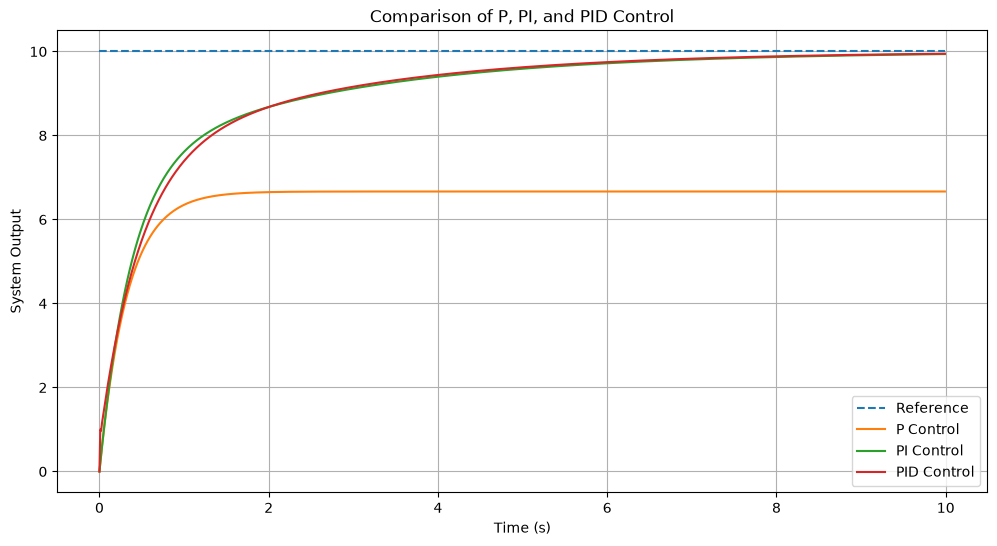

In [9]:
# 9-18D — Controller Output Comparison

plt.figure(figsize=(12, 6))

plt.plot(time, np.full_like(time, reference),
         linestyle="--", label="Reference")

plt.plot(time_p, output_p, label="P Control")
plt.plot(time_pi, output_pi, label="PI Control")
plt.plot(time_pid, output_pid, label="PID Control")

plt.xlabel("Time (s)")
plt.ylabel("System Output")
plt.title("Comparison of P, PI, and PID Control")
plt.grid(True)
plt.legend()
plt.show()

## Control Input Comparison

The control input shows how aggressively each controller responds to the tracking error.

Large or rapidly changing control inputs may indicate:

- Aggressive controller gains.
- Overshoot or oscillation.
- Sensitivity to error changes.

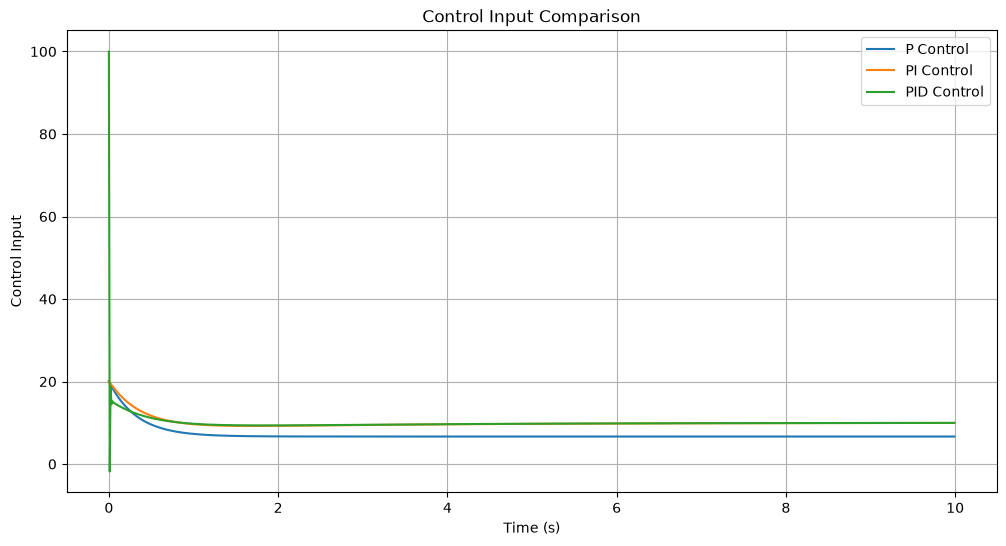

In [10]:
# 10-18D — Control Input Comparison

plt.figure(figsize=(12, 6))

plt.plot(time_p, control_p, label="P Control")
plt.plot(time_pi, control_pi, label="PI Control")
plt.plot(time_pid, control_pid, label="PID Control")

plt.xlabel("Time (s)")
plt.ylabel("Control Input")
plt.title("Control Input Comparison")
plt.grid(True)
plt.legend()
plt.show()

## Tracking Error Comparison

The tracking error is:

\[
e(t) = r(t) - y(t)
\]

The error response is used to evaluate how quickly and accurately the system follows the reference.

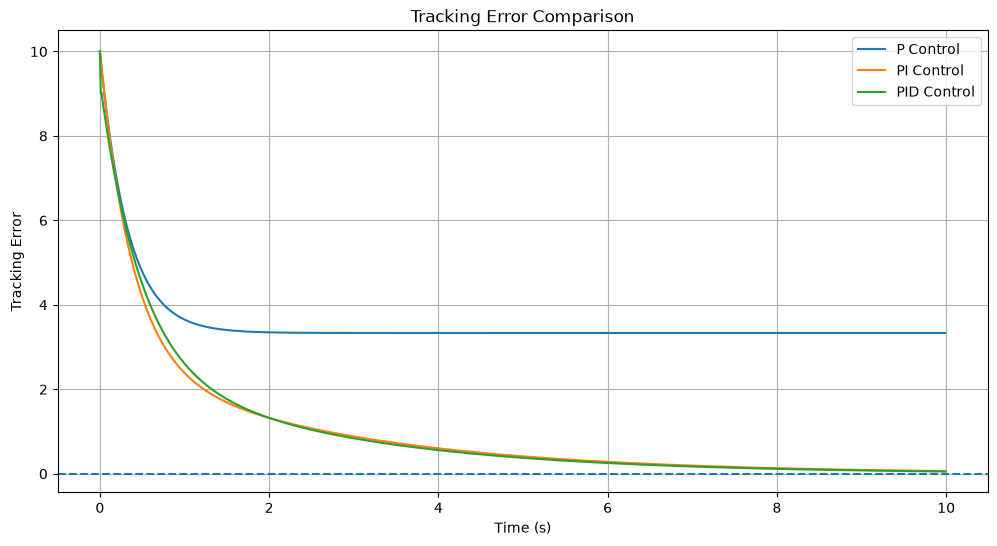

In [11]:
# 11-18D — Tracking Error Comparison

plt.figure(figsize=(12, 6))

plt.plot(time_p, error_p, label="P Control")
plt.plot(time_pi, error_pi, label="PI Control")
plt.plot(time_pid, error_pid, label="PID Control")

plt.axhline(0.0, linestyle="--")

plt.xlabel("Time (s)")
plt.ylabel("Tracking Error")
plt.title("Tracking Error Comparison")
plt.grid(True)
plt.legend()
plt.show()

## Performance Metrics

The following metrics are calculated:

- Mean Absolute Error (MAE)
- Maximum Absolute Error
- Final Absolute Error

Mean Absolute Error:

\[
MAE = \frac{1}{N}\sum_{i=1}^{N}|e_i|
\]

In [12]:
# 12-18D — Performance Metric Evaluation

def calculate_metrics(error):
    mae = np.mean(np.abs(error))
    maximum_error = np.max(np.abs(error))
    final_error = np.abs(error[-1])

    return mae, maximum_error, final_error


metrics = {
    "P Control": calculate_metrics(error_p),
    "PI Control": calculate_metrics(error_pi),
    "PID Control": calculate_metrics(error_pid)
}

for controller_name, values in metrics.items():
    mae, maximum_error, final_error = values

    print(f"\n{controller_name}")
    print(f"MAE: {mae:.4f}")
    print(f"Maximum absolute error: {maximum_error:.4f}")
    print(f"Final absolute error: {final_error:.4f}")


P Control
MAE: 3.5556
Maximum absolute error: 10.0000
Final absolute error: 3.3333

PI Control
MAE: 0.9840
Maximum absolute error: 10.0000
Final absolute error: 0.0613

PID Control
MAE: 0.9868
Maximum absolute error: 10.0000
Final absolute error: 0.0523


## Gain Variation

The proportional gain is varied to observe its influence on the system response.

Increasing the proportional gain generally increases the controller's response to the current error.

However, excessive gain may cause overshoot, oscillations, or instability depending on the system dynamics.

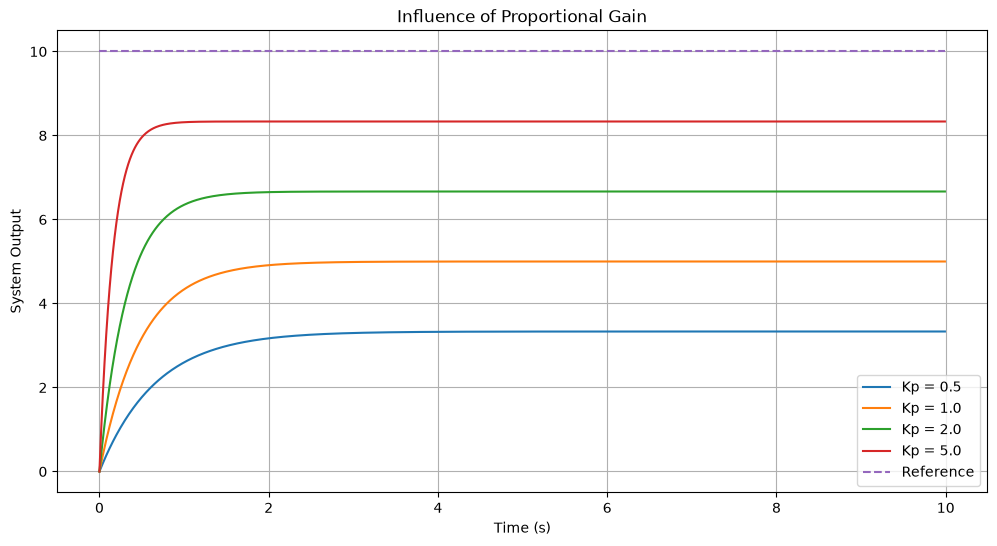

In [13]:
# 13-18D — Proportional Gain Evaluation

kp_values = [0.5, 1.0, 2.0, 5.0]

plt.figure(figsize=(12, 6))

for kp_value in kp_values:
    controller = PIDController(
        kp=kp_value,
        ki=0.0,
        kd=0.0,
        dt=dt,
        output_limits=(-100.0, 100.0)
    )

    time_test, output_test, _, _ = simulate_pid(
        controller=controller,
        reference=reference,
        dt=dt,
        simulation_time=simulation_time,
        system_gain=system_gain,
        time_constant=time_constant,
        initial_output=initial_output
    )

    plt.plot(
        time_test,
        output_test,
        label=f"Kp = {kp_value}"
    )

plt.plot(
    time,
    np.full_like(time, reference),
    linestyle="--",
    label="Reference"
)

plt.xlabel("Time (s)")
plt.ylabel("System Output")
plt.title("Influence of Proportional Gain")
plt.grid(True)
plt.legend()
plt.show()

## PID Gain Evaluation

The PID controller's response depends on the selected gains:

- \(K_p\): Influences the response to the current error.
- \(K_i\): Reduces accumulated steady-state error.
- \(K_d\): Responds to the rate of change of error.

The selected gains in this notebook are intended for demonstrating controller behaviour. They are not vehicle-specific gains and should not be directly applied to a physical vehicle without further modelling, tuning, and validation.

In [14]:
# 14-18D — Final PID Performance Summary

final_mae = np.mean(np.abs(error_pid))
final_max_error = np.max(np.abs(error_pid))
final_absolute_error = np.abs(error_pid[-1])

print("Final PID Performance")
print("---------------------")
print(f"Mean Absolute Error: {final_mae:.4f}")
print(f"Maximum Absolute Error: {final_max_error:.4f}")
print(f"Final Absolute Error: {final_absolute_error:.4f}")
print(f"Final System Output: {output_pid[-1]:.4f}")

Final PID Performance
---------------------
Mean Absolute Error: 0.9868
Maximum Absolute Error: 10.0000
Final Absolute Error: 0.0523
Final System Output: 9.9477


## Conclusions

The experiment demonstrates the fundamental behaviour of PID control.

Key observations:

1. Proportional control responds to the current tracking error.
2. Integral control accumulates error and can reduce steady-state error.
3. Derivative control responds to changes in error.
4. The combined PID controller depends on appropriate gain selection.
5. Controller performance must be evaluated using tracking error and system response.

The first-order system used here is a simplified model. Further work can apply PID control to vehicle speed regulation or longitudinal vehicle control.

In [15]:
# 15-18D — Notebook Validation

assert len(time_pid) == len(output_pid)
assert len(output_pid) == len(error_pid)
assert np.all(np.isfinite(output_pid))
assert np.all(np.isfinite(control_pid))
assert np.all(np.isfinite(error_pid))

print("PID simulation validation completed successfully.")
print("All output arrays have valid dimensions and finite values.")

PID simulation validation completed successfully.
All output arrays have valid dimensions and finite values.


## Extended Controller Performance Evaluation

Additional time-domain metrics are used to evaluate controller performance:

- Rise time: Time required for the output to reach 90% of the reference.
- Settling time: Time required for the output to remain within a defined tolerance band.
- Overshoot: Maximum output above the reference, expressed as a percentage.

These metrics provide a more comprehensive evaluation than final error alone.

In [16]:
# 16-18D — Time-Domain Performance Metrics

def calculate_response_metrics(
    time,
    output,
    reference,
    tolerance=0.02
):
    absolute_error = np.abs(reference - output)

    # Rise time: first time output reaches 90% of reference
    target_90 = 0.9 * abs(reference)

    rise_indices = np.where(
        np.abs(output) >= target_90
    )[0]

    if len(rise_indices) > 0:
        rise_time = time[rise_indices[0]]
    else:
        rise_time = np.nan

    # Settling time: output remains within tolerance band
    tolerance_band = tolerance * abs(reference)

    outside_band = np.where(
        absolute_error > tolerance_band
    )[0]

    if len(outside_band) > 0:
        last_outside_index = outside_band[-1]

        if last_outside_index < len(time) - 1:
            settling_time = time[last_outside_index + 1]
        else:
            settling_time = np.nan
    else:
        settling_time = 0.0

    # Overshoot
    maximum_output = np.max(output)

    if reference != 0:
        overshoot = max(
            0.0,
            (maximum_output - reference)
            / abs(reference) * 100
        )
    else:
        overshoot = np.nan

    return {
        "Rise Time (s)": rise_time,
        "Settling Time (s)": settling_time,
        "Overshoot (%)": overshoot,
        "MAE": np.mean(absolute_error),
        "Final Absolute Error": absolute_error[-1]
    }

## Performance Metrics for the PID Controller

The following cell calculates the extended metrics for the PID response.

The settling-time tolerance is set to ±2% of the reference value.

In [17]:
# 17-18D — PID Response Metrics

pid_metrics = calculate_response_metrics(
    time=time_pid,
    output=output_pid,
    reference=reference,
    tolerance=0.02
)

print("PID Response Metrics")
print("--------------------")

for metric, value in pid_metrics.items():
    print(f"{metric}: {value:.4f}")

PID Response Metrics
--------------------
Rise Time (s): 2.5900
Settling Time (s): 6.6000
Overshoot (%): 0.0000
MAE: 0.9868
Final Absolute Error: 0.0523


## PID Gain Combination Comparison

Different gain combinations are tested to examine their influence on:

- Tracking accuracy
- Settling time
- Overshoot
- Control response

The tested gains are demonstration values for the simplified first-order system.
They are not tuned vehicle-controller parameters.

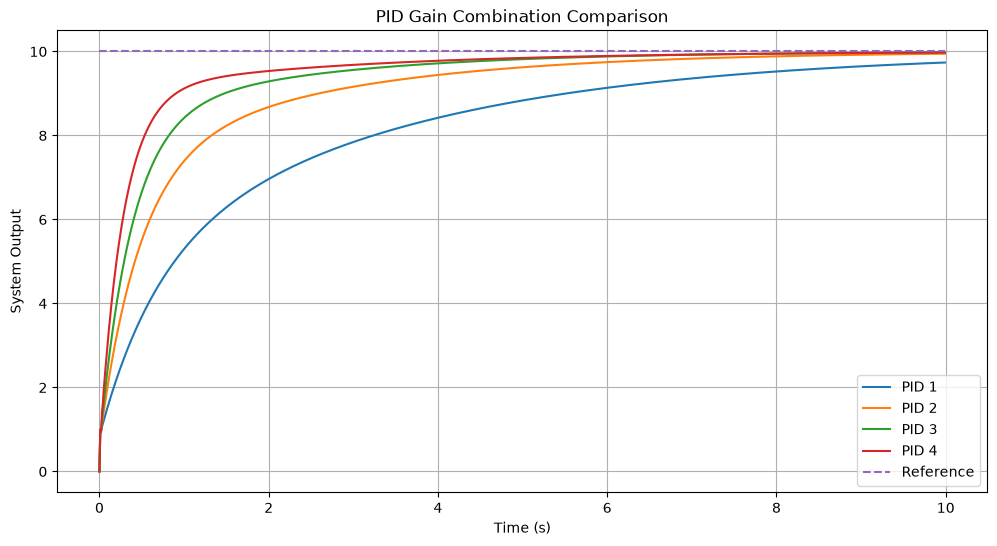

In [18]:
# 18-18D — PID Gain Combination Evaluation

gain_combinations = [
    {"name": "PID 1", "kp": 1.0, "ki": 0.5, "kd": 0.1},
    {"name": "PID 2", "kp": 2.0, "ki": 1.0, "kd": 0.2},
    {"name": "PID 3", "kp": 3.0, "ki": 1.5, "kd": 0.3},
    {"name": "PID 4", "kp": 5.0, "ki": 2.0, "kd": 0.5}
]

gain_results = []

plt.figure(figsize=(12, 6))

for gains in gain_combinations:
    controller = PIDController(
        kp=gains["kp"],
        ki=gains["ki"],
        kd=gains["kd"],
        dt=dt,
        output_limits=(-100.0, 100.0)
    )

    test_time, test_output, _, test_error = simulate_pid(
        controller=controller,
        reference=reference,
        dt=dt,
        simulation_time=simulation_time,
        system_gain=system_gain,
        time_constant=time_constant,
        initial_output=initial_output
    )

    metrics = calculate_response_metrics(
        time=test_time,
        output=test_output,
        reference=reference,
        tolerance=0.02
    )

    gain_results.append({
        "Controller": gains["name"],
        "Kp": gains["kp"],
        "Ki": gains["ki"],
        "Kd": gains["kd"],
        **metrics
    })

    plt.plot(
        test_time,
        test_output,
        label=gains["name"]
    )

plt.plot(
    time,
    np.full_like(time, reference),
    linestyle="--",
    label="Reference"
)

plt.xlabel("Time (s)")
plt.ylabel("System Output")
plt.title("PID Gain Combination Comparison")
plt.grid(True)
plt.legend()
plt.show()

## Gain Comparison Results

The calculated metrics are displayed in a tabular format.

The results should be interpreted by considering multiple performance measures.
A controller with a low final error may still have undesirable overshoot,
slow settling, or aggressive control input.

In [19]:
# 19-18D — Gain Comparison Results Table

import pandas as pd

gain_results_df = pd.DataFrame(gain_results)

display(gain_results_df.round(4))

,Controller,Kp,Ki,Kd,Rise Time (s),Settling Time (s),Overshoot (%),MAE,Final Absolute Error
0,PID 1,1.0,0.5,0.1,5.52,NaN,0.0,1.9123,0.2624
1,PID 2,2.0,1.0,0.2,2.59,6.60,0.0,0.9868,0.0523
2,PID 3,3.0,1.5,0.3,1.48,4.79,0.0,0.6619,0.0207
3,PID 4,5.0,2.0,0.5,0.91,4.27,0.0,0.4933,0.0246


## Performance Metric Visualisation

The following plots compare settling time, overshoot, and mean absolute error
for the tested PID gain combinations.

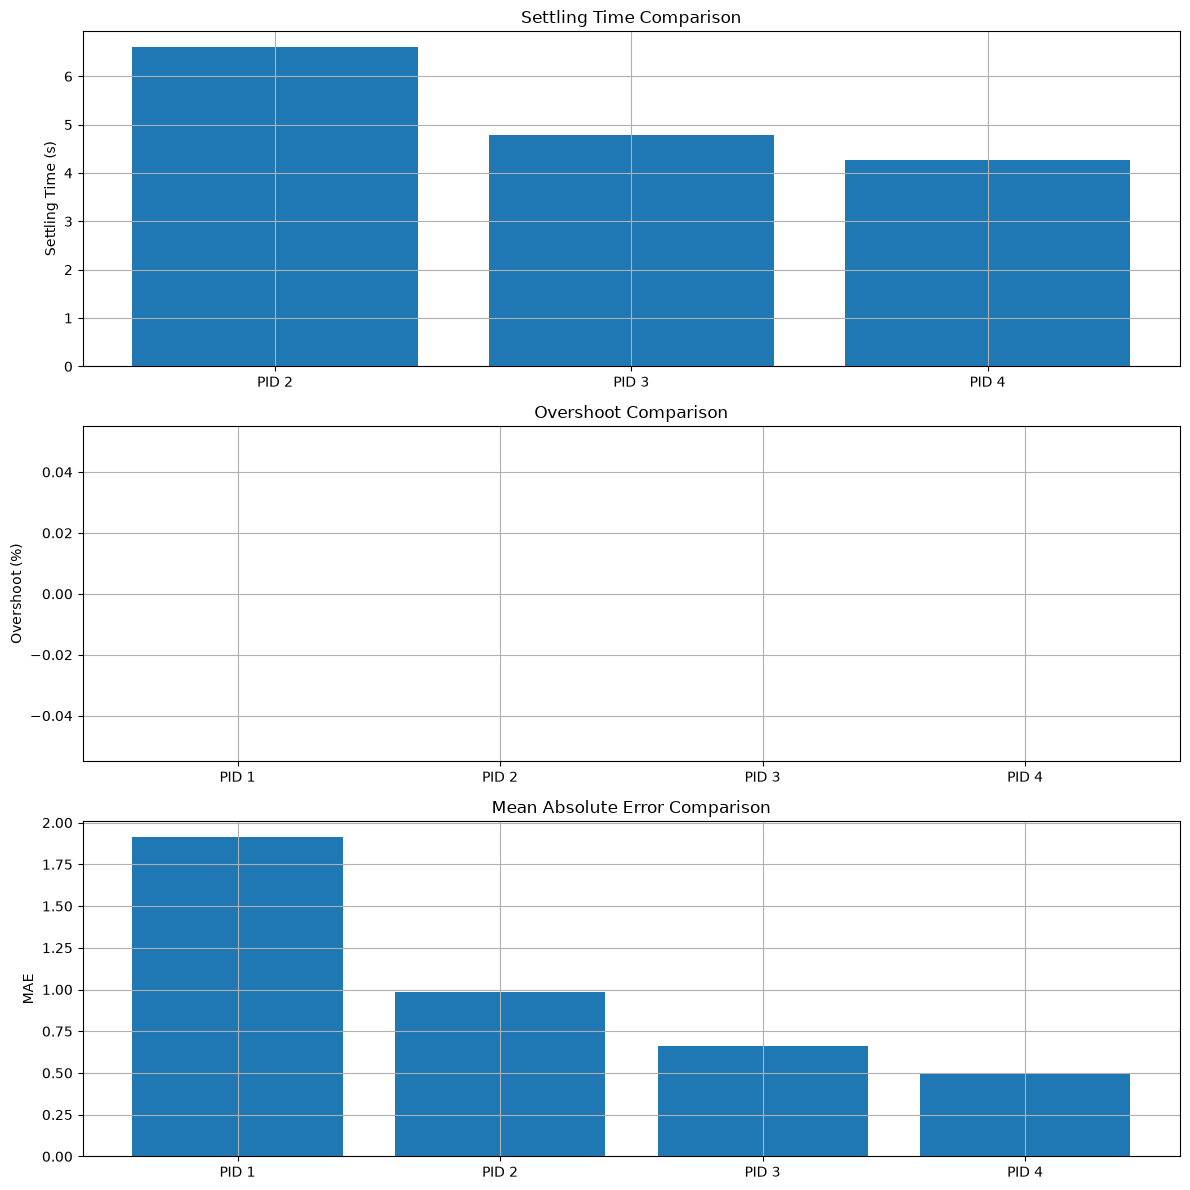

In [20]:
# 20-18D — Gain Performance Metric Visualisation

fig, axes = plt.subplots(3, 1, figsize=(12, 12))

controller_names = gain_results_df["Controller"]

axes[0].bar(
    controller_names,
    gain_results_df["Settling Time (s)"]
)
axes[0].set_title("Settling Time Comparison")
axes[0].set_ylabel("Settling Time (s)")
axes[0].grid(True)

axes[1].bar(
    controller_names,
    gain_results_df["Overshoot (%)"]
)
axes[1].set_title("Overshoot Comparison")
axes[1].set_ylabel("Overshoot (%)")
axes[1].grid(True)

axes[2].bar(
    controller_names,
    gain_results_df["MAE"]
)
axes[2].set_title("Mean Absolute Error Comparison")
axes[2].set_ylabel("MAE")
axes[2].grid(True)

plt.tight_layout()
plt.show()

## Extended Evaluation Summary

The gain comparison demonstrates that PID performance depends on the relationship
between the controller gains and the system dynamics.

The evaluation should consider:

1. Steady-state tracking accuracy.
2. Settling time.
3. Overshoot.
4. Mean absolute error.
5. Control-input magnitude and smoothness.

No single metric is sufficient to evaluate a controller for automotive applications.

In [21]:
# 21-18D — Extended Evaluation Summary

best_mae_index = gain_results_df["MAE"].idxmin()
best_settling_index = gain_results_df["Settling Time (s)"].idxmin()

print("Extended Evaluation Summary")
print("---------------------------")

print(
    "Lowest MAE:",
    gain_results_df.loc[best_mae_index, "Controller"]
)

print(
    "Lowest settling time among valid results:",
    gain_results_df.loc[best_settling_index, "Controller"]
)

print("\nComplete gain comparison:")
display(gain_results_df.round(4))

Extended Evaluation Summary
---------------------------
Lowest MAE: PID 4
Lowest settling time among valid results: PID 4

Complete gain comparison:


,Controller,Kp,Ki,Kd,Rise Time (s),Settling Time (s),Overshoot (%),MAE,Final Absolute Error
0,PID 1,1.0,0.5,0.1,5.52,NaN,0.0,1.9123,0.2624
1,PID 2,2.0,1.0,0.2,2.59,6.60,0.0,0.9868,0.0523
2,PID 3,3.0,1.5,0.3,1.48,4.79,0.0,0.6619,0.0207
3,PID 4,5.0,2.0,0.5,0.91,4.27,0.0,0.4933,0.0246


## Validation

The extended evaluation is validated by checking:

- The number of gain combinations.
- The presence of calculated performance metrics.
- The absence of invalid numerical values in the system outputs.

In [22]:
# 22-18D — Extended Evaluation Validation

assert len(gain_results_df) == len(gain_combinations)

required_columns = [
    "Controller",
    "Kp",
    "Ki",
    "Kd",
    "Rise Time (s)",
    "Settling Time (s)",
    "Overshoot (%)",
    "MAE",
    "Final Absolute Error"
]

for column in required_columns:
    assert column in gain_results_df.columns

assert np.all(
    np.isfinite(gain_results_df["MAE"])
)

assert np.all(
    np.isfinite(gain_results_df["Final Absolute Error"])
)

print("Extended PID evaluation validation completed successfully.")

Extended PID evaluation validation completed successfully.


## PID-Based Vehicle Speed Control

The PID controller is now applied to a simplified longitudinal vehicle model.

The objective is to make the vehicle follow a desired speed reference.

The longitudinal vehicle dynamics are represented by:

m * dv/dt = F_drive - F_resistance

where:

- m is the vehicle mass.
- v is vehicle velocity.
- F_drive is the driving force.
- F_resistance includes rolling resistance and aerodynamic drag.

The controller generates an acceleration command based on the speed tracking error.

In [23]:
# 23-18D — Vehicle Speed Control Parameters

vehicle_mass = 1200.0       # kg
rolling_resistance = 150.0  # N
drag_coefficient = 0.35
frontal_area = 2.2          # m²
air_density = 1.225         # kg/m³
gravity = 9.81              # m/s²

speed_reference = 15.0      # m/s
initial_speed = 0.0         # m/s

speed_simulation_time = 20.0
speed_dt = 0.01

speed_time = np.arange(
    0,
    speed_simulation_time,
    speed_dt
)

print("Vehicle mass:", vehicle_mass, "kg")
print("Target speed:", speed_reference, "m/s")
print("Simulation duration:", speed_simulation_time, "seconds")

Vehicle mass: 1200.0 kg
Target speed: 15.0 m/s
Simulation duration: 20.0 seconds


## Longitudinal Vehicle Model

The resistance forces are approximated using:

Rolling resistance:

F_roll = C_roll * m * g

Aerodynamic drag:

F_drag = 0.5 * rho * C_d * A * v²

The net acceleration is:

a = (F_drive - F_roll - F_drag) / m

The velocity is updated using forward Euler integration.

In [24]:
# 24-18D — Longitudinal Vehicle Model

def calculate_resistance(speed):
    rolling_force = rolling_resistance

    aerodynamic_force = (
        0.5
        * air_density
        * drag_coefficient
        * frontal_area
        * speed**2
    )

    total_resistance = (
        rolling_force + aerodynamic_force
    )

    return total_resistance


def update_vehicle_speed(
    speed,
    acceleration_command,
    dt
):
    resistance_force = calculate_resistance(speed)

    drive_force = vehicle_mass * acceleration_command

    net_force = drive_force - resistance_force

    acceleration = net_force / vehicle_mass

    updated_speed = speed + acceleration * dt

    updated_speed = max(0.0, updated_speed)

    return updated_speed, acceleration

## Speed Controller Simulation

The PID controller generates an acceleration command.

The acceleration command is limited to a practical range:

- Maximum acceleration: 3 m/s²
- Maximum braking deceleration: -4 m/s²

These limits represent simplified actuator constraints and are not validated vehicle parameters.

In [25]:
# 25-18D — PID Vehicle Speed Simulation

speed_pid = PIDController(
    kp=0.8,
    ki=0.15,
    kd=0.05,
    dt=speed_dt,
    output_limits=(-4.0, 3.0)
)

vehicle_speed = np.zeros(len(speed_time))
vehicle_acceleration = np.zeros(len(speed_time))
vehicle_force = np.zeros(len(speed_time))
vehicle_error = np.zeros(len(speed_time))

vehicle_speed[0] = initial_speed

speed_pid.reset()

for i in range(len(speed_time) - 1):
    error = speed_reference - vehicle_speed[i]

    acceleration_command = speed_pid.compute(error)

    updated_speed, actual_acceleration = update_vehicle_speed(
        speed=vehicle_speed[i],
        acceleration_command=acceleration_command,
        dt=speed_dt
    )

    vehicle_speed[i + 1] = updated_speed
    vehicle_acceleration[i] = actual_acceleration
    vehicle_force[i] = vehicle_mass * acceleration_command
    vehicle_error[i] = error

vehicle_error[-1] = speed_reference - vehicle_speed[-1]
vehicle_acceleration[-1] = vehicle_acceleration[-2]
vehicle_force[-1] = vehicle_force[-2]

print("Final vehicle speed:", vehicle_speed[-1], "m/s")
print("Final speed error:", vehicle_error[-1], "m/s")

Final vehicle speed: 15.373468722741748 m/s
Final speed error: -0.37346872274174814 m/s


## Vehicle Speed Response

The speed response is compared with the desired reference.

The plot illustrates whether the PID controller can bring the vehicle to the target speed while considering resistance forces and acceleration limits.

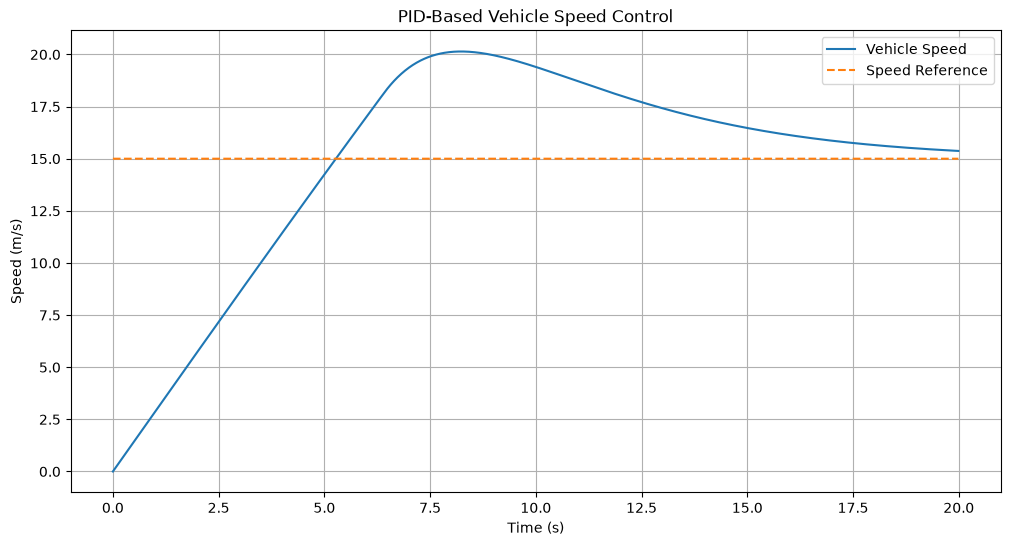

In [26]:
# 26-18D — Vehicle Speed Response

plt.figure(figsize=(12, 6))

plt.plot(
    speed_time,
    vehicle_speed,
    label="Vehicle Speed"
)

plt.plot(
    speed_time,
    np.full_like(speed_time, speed_reference),
    linestyle="--",
    label="Speed Reference"
)

plt.xlabel("Time (s)")
plt.ylabel("Speed (m/s)")
plt.title("PID-Based Vehicle Speed Control")
plt.grid(True)
plt.legend()
plt.show()

## Vehicle Acceleration Response

The acceleration response is evaluated to observe the controller's influence on vehicle longitudinal motion.

The acceleration command is limited to the defined actuator range.

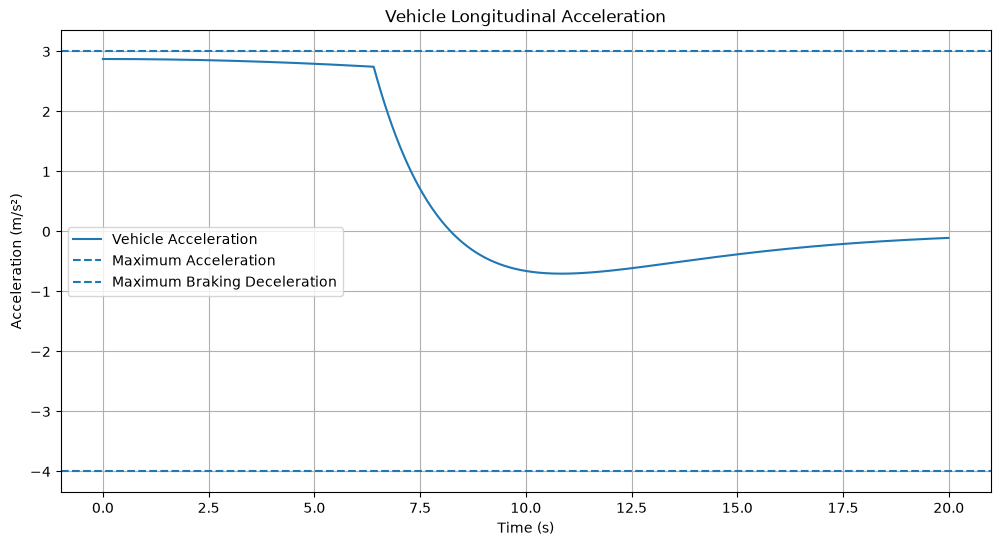

In [27]:
# 27-18D — Vehicle Acceleration Response

plt.figure(figsize=(12, 6))

plt.plot(
    speed_time,
    vehicle_acceleration,
    label="Vehicle Acceleration"
)

plt.axhline(
    3.0,
    linestyle="--",
    label="Maximum Acceleration"
)

plt.axhline(
    -4.0,
    linestyle="--",
    label="Maximum Braking Deceleration"
)

plt.xlabel("Time (s)")
plt.ylabel("Acceleration (m/s²)")
plt.title("Vehicle Longitudinal Acceleration")
plt.grid(True)
plt.legend()
plt.show()

## Vehicle Speed Tracking Metrics

The following metrics are calculated:

- Mean Absolute Speed Error
- Maximum Absolute Speed Error
- Final Absolute Speed Error
- Maximum vehicle speed
- Maximum acceleration
- Minimum acceleration

In [28]:
# 28-18D — Vehicle Speed Performance Metrics

speed_mae = np.mean(np.abs(vehicle_error))
speed_max_error = np.max(np.abs(vehicle_error))
speed_final_error = np.abs(vehicle_error[-1])

maximum_vehicle_speed = np.max(vehicle_speed)
maximum_acceleration = np.max(vehicle_acceleration)
minimum_acceleration = np.min(vehicle_acceleration)

print("Vehicle Speed Control Metrics")
print("-----------------------------")
print(f"Mean Absolute Speed Error: {speed_mae:.4f} m/s")
print(f"Maximum Absolute Speed Error: {speed_max_error:.4f} m/s")
print(f"Final Absolute Speed Error: {speed_final_error:.4f} m/s")
print(f"Maximum Vehicle Speed: {maximum_vehicle_speed:.4f} m/s")
print(f"Maximum Acceleration: {maximum_acceleration:.4f} m/s²")
print(f"Minimum Acceleration: {minimum_acceleration:.4f} m/s²")

Vehicle Speed Control Metrics
-----------------------------
Mean Absolute Speed Error: 3.8059 m/s
Maximum Absolute Speed Error: 15.0000 m/s
Final Absolute Speed Error: 0.3735 m/s
Maximum Vehicle Speed: 20.1418 m/s
Maximum Acceleration: 2.8750 m/s²
Minimum Acceleration: -0.7027 m/s²


## Interpretation

The speed controller is evaluated using both tracking accuracy and vehicle dynamics.

A suitable speed controller should:

1. Follow the target speed.
2. Maintain a low steady-state error.
3. Avoid unnecessary oscillations.
4. Respect acceleration and braking limits.
5. Produce physically reasonable control behaviour.

The model is simplified and does not include a powertrain model, gear selection,
engine or motor torque limits, actuator delay, or road gradient.

In [29]:
# 29-18D — Vehicle Speed Control Validation

assert len(vehicle_speed) == len(speed_time)
assert len(vehicle_error) == len(speed_time)

assert np.all(np.isfinite(vehicle_speed))
assert np.all(np.isfinite(vehicle_acceleration))
assert np.all(np.isfinite(vehicle_error))

assert np.min(vehicle_speed) >= 0.0

print("Vehicle speed control validation completed successfully.")

Vehicle speed control validation completed successfully.


## Systematic PID Gain Tuning

The previous simulation showed considerable speed overshoot.

This section compares multiple PID gain combinations to investigate the
relationship between controller gains and vehicle speed response.

The evaluation focuses on:

- Mean Absolute Error (MAE)
- Maximum speed overshoot
- Settling time
- Final speed error

The objective is to identify gain combinations that provide a balanced
speed response without assuming that one combination is universally optimal.

In [30]:
# 30-18D — PID Gain Tuning Parameters

tuning_combinations = [
    {"name": "Tuning 1", "kp": 0.30, "ki": 0.03, "kd": 0.02},
    {"name": "Tuning 2", "kp": 0.40, "ki": 0.05, "kd": 0.04},
    {"name": "Tuning 3", "kp": 0.50, "ki": 0.08, "kd": 0.06},
    {"name": "Tuning 4", "kp": 0.60, "ki": 0.10, "kd": 0.08},
    {"name": "Tuning 5", "kp": 0.70, "ki": 0.12, "kd": 0.10},
    {"name": "Tuning 6", "kp": 0.80, "ki": 0.15, "kd": 0.05}
]

print("Number of gain combinations:", len(tuning_combinations))

Number of gain combinations: 6


## Vehicle Speed Performance Metrics

The overshoot calculation is based on the maximum vehicle speed above
the desired reference.

Settling time is calculated using a ±2% speed tolerance band.

A settling time of NaN indicates that the vehicle did not remain within
the tolerance band until the end of the simulation.

In [32]:
# 31-18D — Vehicle Speed Performance Metric Function

def calculate_speed_metrics(
    time,
    speed,
    reference,
    tolerance=0.02
):
    error = reference - speed
    absolute_error = np.abs(error)

    mae = np.mean(absolute_error)
    final_error = absolute_error[-1]

    maximum_speed = np.max(speed)

    overshoot = max(
        0.0,
        (maximum_speed - reference)
        / abs(reference) * 100
    )

    tolerance_band = tolerance * abs(reference)

    outside_band = np.where(
        absolute_error > tolerance_band
    )[0]

    if len(outside_band) == 0:
        settling_time = 0.0

    else:
        last_outside_index = outside_band[-1]

        if last_outside_index < len(time) - 1:
            settling_time = time[last_outside_index + 1]
        else:
            settling_time = np.nan

    return {
        "MAE (m/s)": mae,
        "Maximum Speed (m/s)": maximum_speed,
        "Overshoot (%)": overshoot,
        "Settling Time (s)": settling_time,
        "Final Absolute Error (m/s)": final_error
    }

## Gain Combination Simulation

Each gain combination is applied to the same vehicle model and simulation
conditions.

The same acceleration limits are maintained for every controller to ensure
that the comparison is performed under consistent constraints.

In [33]:
# 32-18D — Systematic PID Gain Simulation

import pandas as pd

tuning_results = []
tuning_responses = {}

for gains in tuning_combinations:
    controller = PIDController(
        kp=gains["kp"],
        ki=gains["ki"],
        kd=gains["kd"],
        dt=speed_dt,
        output_limits=(-4.0, 3.0)
    )

    test_speed = np.zeros(len(speed_time))
    test_acceleration = np.zeros(len(speed_time))
    test_error = np.zeros(len(speed_time))

    test_speed[0] = initial_speed
    controller.reset()

    for i in range(len(speed_time) - 1):
        error = speed_reference - test_speed[i]

        acceleration_command = controller.compute(error)

        updated_speed, actual_acceleration = (
            update_vehicle_speed(
                speed=test_speed[i],
                acceleration_command=acceleration_command,
                dt=speed_dt
            )
        )

        test_speed[i + 1] = updated_speed
        test_acceleration[i] = actual_acceleration
        test_error[i] = error

    test_error[-1] = speed_reference - test_speed[-1]
    test_acceleration[-1] = test_acceleration[-2]

    metrics = calculate_speed_metrics(
        time=speed_time,
        speed=test_speed,
        reference=speed_reference,
        tolerance=0.02
    )

    result = {
        "Controller": gains["name"],
        "Kp": gains["kp"],
        "Ki": gains["ki"],
        "Kd": gains["kd"],
        **metrics
    }

    tuning_results.append(result)

    tuning_responses[gains["name"]] = {
        "speed": test_speed,
        "acceleration": test_acceleration,
        "error": test_error
    }

tuning_results_df = pd.DataFrame(tuning_results)

display(tuning_results_df.round(4))

,Controller,Kp,Ki,Kd,MAE (m/s),Maximum Speed (m/s),Overshoot (%),Settling Time (s),Final Absolute Error (m/s)
0,Tuning 1,0.3,0.03,0.02,3.3464,17.3706,15.8042,NaN,1.4753
1,Tuning 2,0.4,0.05,0.04,3.5216,18.0477,20.3182,NaN,1.0137
2,Tuning 3,0.5,0.08,0.06,3.7336,19.0322,26.8815,NaN,0.5707
3,Tuning 4,0.6,0.10,0.08,3.7603,19.3658,29.1055,NaN,0.4889
4,Tuning 5,0.7,0.12,0.10,3.7741,19.6183,30.7887,NaN,0.4568
5,Tuning 6,0.8,0.15,0.05,3.8059,20.1418,34.2788,NaN,0.3735


## Speed Response Comparison

The speed responses of all tested gain combinations are plotted against
the target speed.

This visual comparison helps identify differences in acceleration,
overshoot, and convergence behaviour.

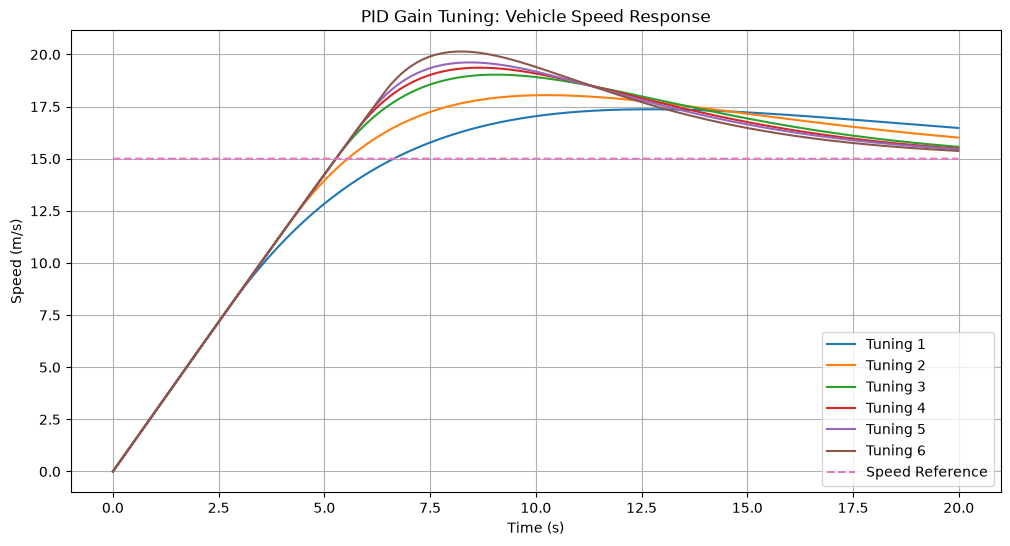

In [34]:
# 33-18D — Tuned Speed Response Comparison

plt.figure(figsize=(12, 6))

for gains in tuning_combinations:
    response = tuning_responses[gains["name"]]

    plt.plot(
        speed_time,
        response["speed"],
        label=gains["name"]
    )

plt.plot(
    speed_time,
    np.full_like(speed_time, speed_reference),
    linestyle="--",
    label="Speed Reference"
)

plt.xlabel("Time (s)")
plt.ylabel("Speed (m/s)")
plt.title("PID Gain Tuning: Vehicle Speed Response")
plt.grid(True)
plt.legend()
plt.show()

## Overshoot and Settling-Time Comparison

Overshoot and settling time are compared to understand the transient
behaviour of each gain combination.

A lower overshoot does not necessarily guarantee better overall performance.
The result must also be considered together with tracking error and settling time.

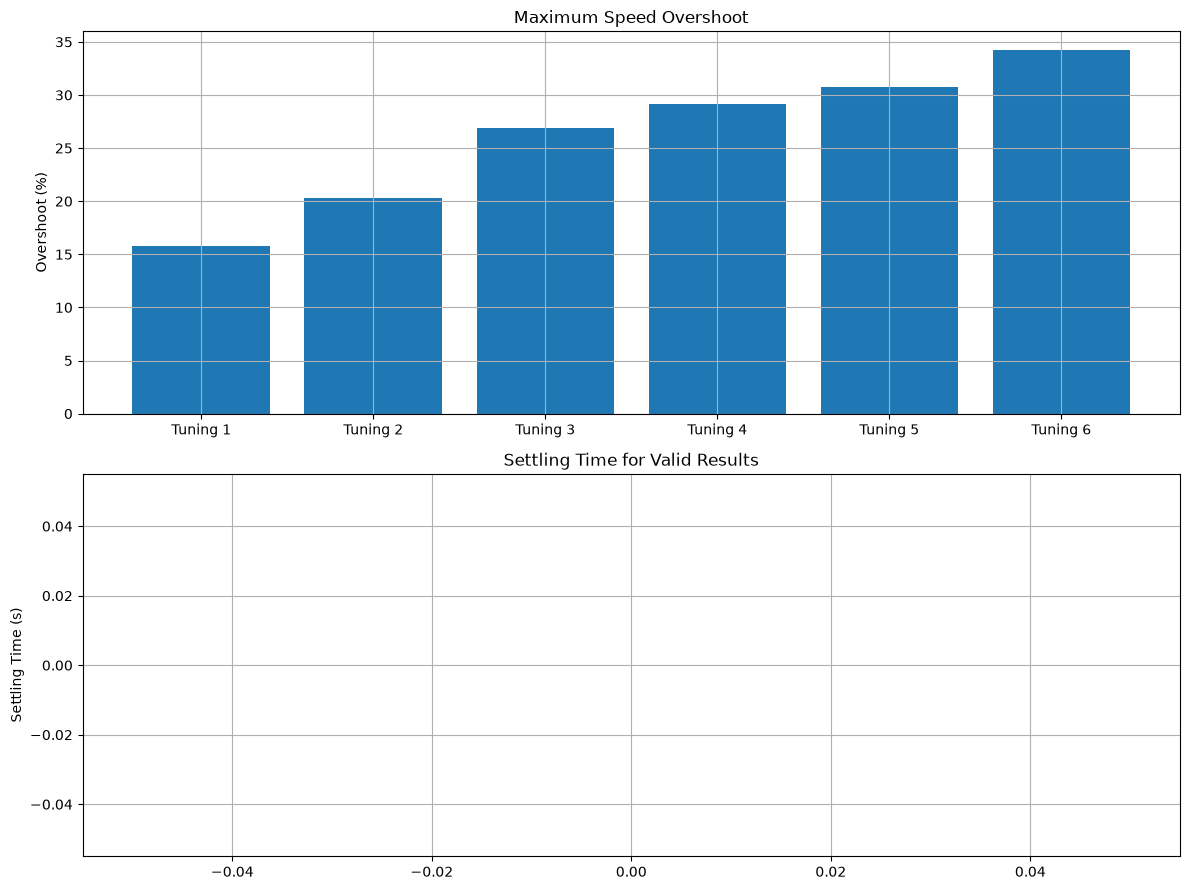

In [35]:
# 34-18D — Overshoot and Settling-Time Comparison

valid_settling_results = tuning_results_df.dropna(
    subset=["Settling Time (s)"]
)

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

axes[0].bar(
    tuning_results_df["Controller"],
    tuning_results_df["Overshoot (%)"]
)

axes[0].set_title("Maximum Speed Overshoot")
axes[0].set_ylabel("Overshoot (%)")
axes[0].grid(True)

axes[1].bar(
    valid_settling_results["Controller"],
    valid_settling_results["Settling Time (s)"]
)

axes[1].set_title("Settling Time for Valid Results")
axes[1].set_ylabel("Settling Time (s)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Mean Absolute Error Comparison

Mean Absolute Error represents the average magnitude of the speed tracking
error over the complete simulation.

It is evaluated together with overshoot and settling time rather than used
as the only controller performance criterion.

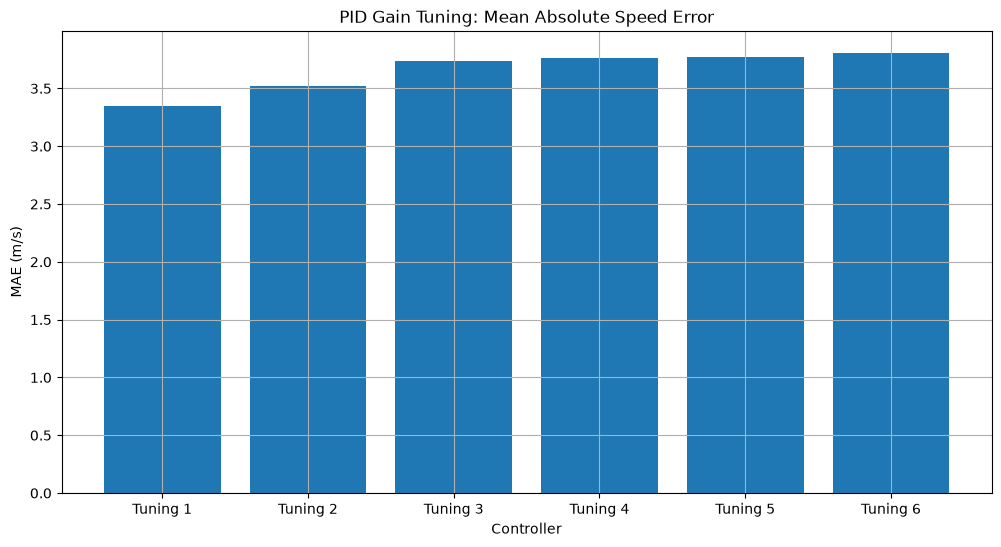

In [36]:
# 35-18D — Mean Absolute Error Comparison

plt.figure(figsize=(12, 6))

plt.bar(
    tuning_results_df["Controller"],
    tuning_results_df["MAE (m/s)"]
)

plt.xlabel("Controller")
plt.ylabel("MAE (m/s)")
plt.title("PID Gain Tuning: Mean Absolute Speed Error")
plt.grid(True)
plt.show()

## Gain Tuning Summary

The results are sorted by mean absolute error to simplify comparison.

This ordering is only a numerical arrangement of the measured results.
The controller should be selected based on the intended application,
constraints, and multiple performance metrics.

In [37]:
# 36-18D — Gain Tuning Summary

sorted_tuning_results = tuning_results_df.sort_values(
    by="MAE (m/s)"
).reset_index(drop=True)

display(sorted_tuning_results.round(4))

print("Gain tuning evaluation completed.")

,Controller,Kp,Ki,Kd,MAE (m/s),Maximum Speed (m/s),Overshoot (%),Settling Time (s),Final Absolute Error (m/s)
0,Tuning 1,0.3,0.03,0.02,3.3464,17.3706,15.8042,NaN,1.4753
1,Tuning 2,0.4,0.05,0.04,3.5216,18.0477,20.3182,NaN,1.0137
2,Tuning 3,0.5,0.08,0.06,3.7336,19.0322,26.8815,NaN,0.5707
3,Tuning 4,0.6,0.10,0.08,3.7603,19.3658,29.1055,NaN,0.4889
4,Tuning 5,0.7,0.12,0.10,3.7741,19.6183,30.7887,NaN,0.4568
5,Tuning 6,0.8,0.15,0.05,3.8059,20.1418,34.2788,NaN,0.3735


Gain tuning evaluation completed.


## Validation

The gain tuning experiment is validated by checking:

- All gain combinations were simulated.
- Each response contains the expected number of samples.
- Speed and acceleration values are finite.
- The calculated MAE values are finite.

In [38]:
# 37-18D — Gain Tuning Validation

assert len(tuning_results_df) == len(tuning_combinations)

for controller_name, response in tuning_responses.items():
    assert len(response["speed"]) == len(speed_time)
    assert len(response["acceleration"]) == len(speed_time)
    assert len(response["error"]) == len(speed_time)

    assert np.all(np.isfinite(response["speed"]))
    assert np.all(np.isfinite(response["acceleration"]))
    assert np.all(np.isfinite(response["error"]))

assert np.all(
    np.isfinite(tuning_results_df["MAE (m/s)"])
)

print("PID gain tuning validation completed successfully.")

PID gain tuning validation completed successfully.


## Feedforward Compensation and Anti-Windup

The previous simulations showed significant speed overshoot.

Two improvements are introduced:

1. Feedforward compensation:
   Estimates the acceleration command required to compensate for
   rolling resistance and aerodynamic drag.

2. Integral anti-windup:
   Prevents excessive integral accumulation when the control input
   reaches its limits.

The total acceleration command is:

a_command = a_feedforward + a_feedback

where:

- a_feedforward compensates for estimated resistance.
- a_feedback is generated by the PID controller.

The feedforward term is calculated as:

a_feedforward = F_resistance / m

In [39]:
# 38-18D — Feedforward Compensation Parameters

maximum_acceleration = 3.0
minimum_acceleration = -4.0

print("Maximum acceleration:", maximum_acceleration, "m/s²")
print("Minimum acceleration:", minimum_acceleration, "m/s²")
print("Feedforward compensation enabled.")

Maximum acceleration: 3.0 m/s²
Minimum acceleration: -4.0 m/s²
Feedforward compensation enabled.


## Anti-Windup PID Controller

The anti-windup controller uses conditional integration.

The integral term is updated only when:

- The output is not saturated, or
- The current error would move the saturated output back toward
  the allowable range.

This implementation is intended for a simplified simulation and
does not represent a production-ready automotive controller.

In [40]:
# 39-18D — Anti-Windup PID Controller

class AntiWindupPIDController:
    def __init__(
        self,
        kp,
        ki,
        kd,
        dt,
        output_limits=None
    ):
        self.kp = kp
        self.ki = ki
        self.kd = kd
        self.dt = dt

        self.output_limits = output_limits

        self.previous_error = 0.0
        self.integral = 0.0

    def reset(self):
        self.previous_error = 0.0
        self.integral = 0.0

    def compute(self, error):
        proportional = self.kp * error

        derivative_error = (
            error - self.previous_error
        ) / self.dt

        derivative = self.kd * derivative_error

        # Candidate integral update
        candidate_integral = (
            self.integral + error * self.dt
        )

        integral = self.ki * candidate_integral

        unsaturated_output = (
            proportional
            + integral
            + derivative
        )

        if self.output_limits is not None:
            minimum, maximum = self.output_limits

            saturated_output = np.clip(
                unsaturated_output,
                minimum,
                maximum
            )

            output_is_saturated = (
                saturated_output != unsaturated_output
            )

            error_drives_back_from_limit = (
                (unsaturated_output > maximum and error < 0)
                or
                (unsaturated_output < minimum and error > 0)
            )

            if (
                not output_is_saturated
                or error_drives_back_from_limit
            ):
                self.integral = candidate_integral

            control_output = saturated_output

        else:
            self.integral = candidate_integral
            control_output = unsaturated_output

        self.previous_error = error

        return control_output

## Feedforward-Based Vehicle Speed Simulation

The feedforward term compensates for the resistance force at the
current vehicle speed.

The feedback controller then corrects the remaining speed error.

The combined acceleration command is limited to the defined
acceleration and braking constraints.

In [41]:
# 40-18D — Feedforward and Anti-Windup Simulation

improved_pid = AntiWindupPIDController(
    kp=0.35,
    ki=0.08,
    kd=0.04,
    dt=speed_dt,
    output_limits=(
        minimum_acceleration,
        maximum_acceleration
    )
)

improved_speed = np.zeros(len(speed_time))
improved_acceleration = np.zeros(len(speed_time))
improved_feedforward = np.zeros(len(speed_time))
improved_feedback = np.zeros(len(speed_time))
improved_error = np.zeros(len(speed_time))

improved_speed[0] = initial_speed
improved_pid.reset()

for i in range(len(speed_time) - 1):
    current_speed = improved_speed[i]

    error = speed_reference - current_speed

    resistance_force = calculate_resistance(current_speed)

    feedforward_acceleration = (
        resistance_force / vehicle_mass
    )

    feedback_acceleration = improved_pid.compute(error)

    combined_acceleration = (
        feedforward_acceleration
        + feedback_acceleration
    )

    combined_acceleration = np.clip(
        combined_acceleration,
        minimum_acceleration,
        maximum_acceleration
    )

    updated_speed, actual_acceleration = (
        update_vehicle_speed(
            speed=current_speed,
            acceleration_command=combined_acceleration,
            dt=speed_dt
        )
    )

    improved_speed[i + 1] = updated_speed
    improved_acceleration[i] = actual_acceleration
    improved_feedforward[i] = feedforward_acceleration
    improved_feedback[i] = feedback_acceleration
    improved_error[i] = error

improved_error[-1] = (
    speed_reference - improved_speed[-1]
)

improved_acceleration[-1] = improved_acceleration[-2]
improved_feedforward[-1] = improved_feedforward[-2]
improved_feedback[-1] = improved_feedback[-2]

print("Improved controller simulation completed.")
print("Final speed:", improved_speed[-1], "m/s")
print("Final speed error:", improved_error[-1], "m/s")

Improved controller simulation completed.
Final speed: 15.0674122201632 m/s
Final speed error: -0.06741222016320059 m/s


## Improved Speed Response

The improved controller response is compared against the target speed.

The response is evaluated for:

- Overshoot reduction.
- Speed tracking.
- Final error.
- Overall transient behaviour.

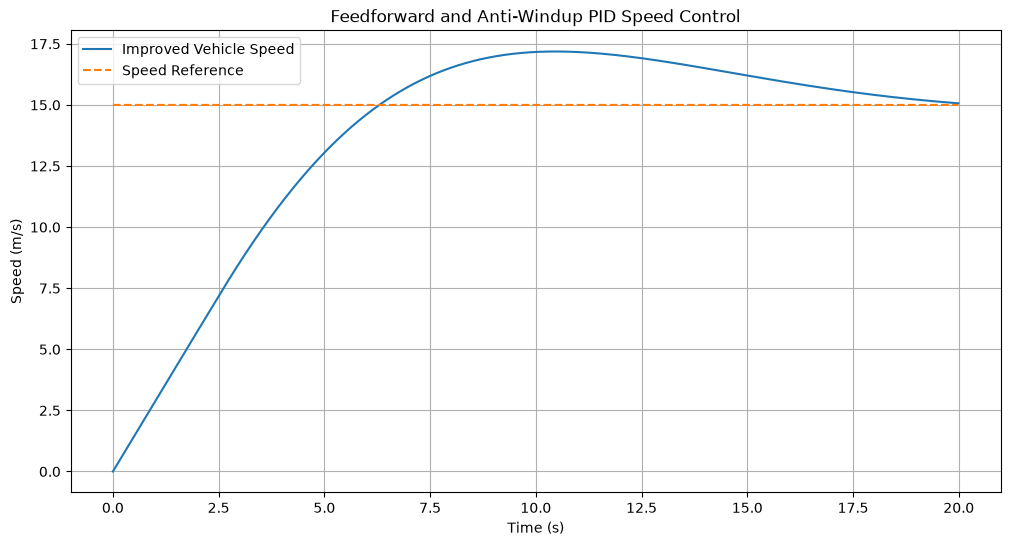

In [42]:
# 41-18D — Improved Speed Response

plt.figure(figsize=(12, 6))

plt.plot(
    speed_time,
    improved_speed,
    label="Improved Vehicle Speed"
)

plt.plot(
    speed_time,
    np.full_like(speed_time, speed_reference),
    linestyle="--",
    label="Speed Reference"
)

plt.xlabel("Time (s)")
plt.ylabel("Speed (m/s)")
plt.title("Feedforward and Anti-Windup PID Speed Control")
plt.grid(True)
plt.legend()
plt.show()

## Feedforward and Feedback Contributions

The feedforward component compensates for estimated resistance.

The feedback component responds to the remaining tracking error.

This separation helps distinguish model-based compensation from
feedback correction.

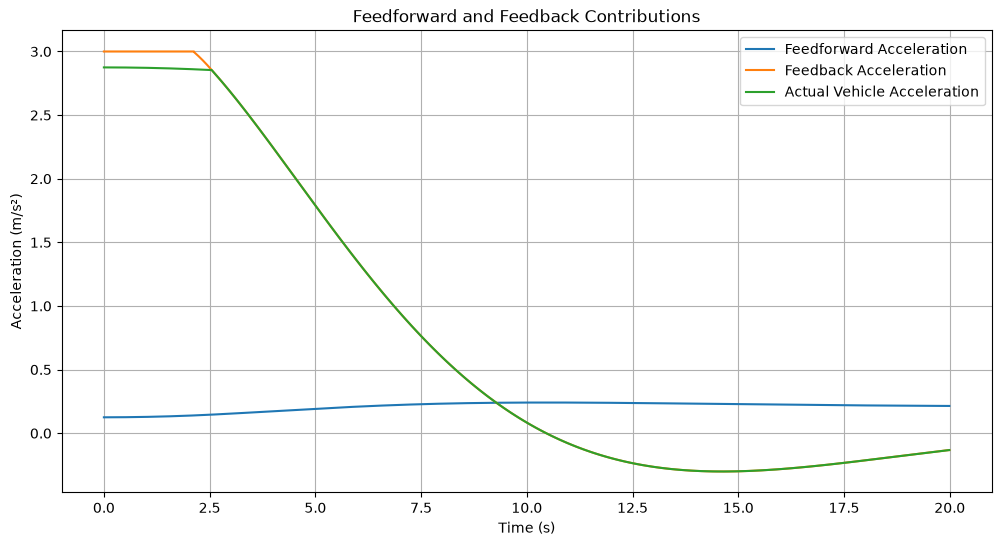

In [43]:
# 42-18D — Feedforward and Feedback Comparison

plt.figure(figsize=(12, 6))

plt.plot(
    speed_time,
    improved_feedforward,
    label="Feedforward Acceleration"
)

plt.plot(
    speed_time,
    improved_feedback,
    label="Feedback Acceleration"
)

plt.plot(
    speed_time,
    improved_acceleration,
    label="Actual Vehicle Acceleration"
)

plt.xlabel("Time (s)")
plt.ylabel("Acceleration (m/s²)")
plt.title("Feedforward and Feedback Contributions")
plt.grid(True)
plt.legend()
plt.show()

## Improved Controller Performance Metrics

The improved controller is evaluated using the same metrics as the
previous speed-control experiment.

This allows a direct comparison with the original controller.

In [44]:
# 43-18D — Improved Controller Metrics

improved_metrics = calculate_speed_metrics(
    time=speed_time,
    speed=improved_speed,
    reference=speed_reference,
    tolerance=0.02
)

print("Improved Controller Metrics")
print("---------------------------")

for metric, value in improved_metrics.items():
    print(f"{metric}: {value:.4f}")

Improved Controller Metrics
---------------------------
MAE (m/s): 2.9384
Maximum Speed (m/s): 17.1872
Overshoot (%): 14.5813
Settling Time (s): 18.5500
Final Absolute Error (m/s): 0.0674


## Original and Improved Controller Comparison

The original and improved controllers are compared using the same
simulation duration and speed reference.

The comparison does not assume that the improved controller will
outperform the original controller in every metric.

In [45]:
# 44-18D — Original and Improved Controller Comparison

original_metrics = calculate_speed_metrics(
    time=speed_time,
    speed=vehicle_speed,
    reference=speed_reference,
    tolerance=0.02
)

comparison_results = pd.DataFrame([
    {
        "Controller": "Original PID",
        **original_metrics
    },
    {
        "Controller": "Feedforward + Anti-Windup PID",
        **improved_metrics
    }
])

display(comparison_results.round(4))

,Controller,MAE (m/s),Maximum Speed (m/s),Overshoot (%),Settling Time (s),Final Absolute Error (m/s)
0,Original PID,3.8059,20.1418,34.2788,NaN,0.3735
1,Feedforward + Anti-Windup PID,2.9384,17.1872,14.5813,18.55,0.0674


## Speed Response Comparison

The original and improved controller responses are plotted together
to observe the effect of feedforward compensation and anti-windup.

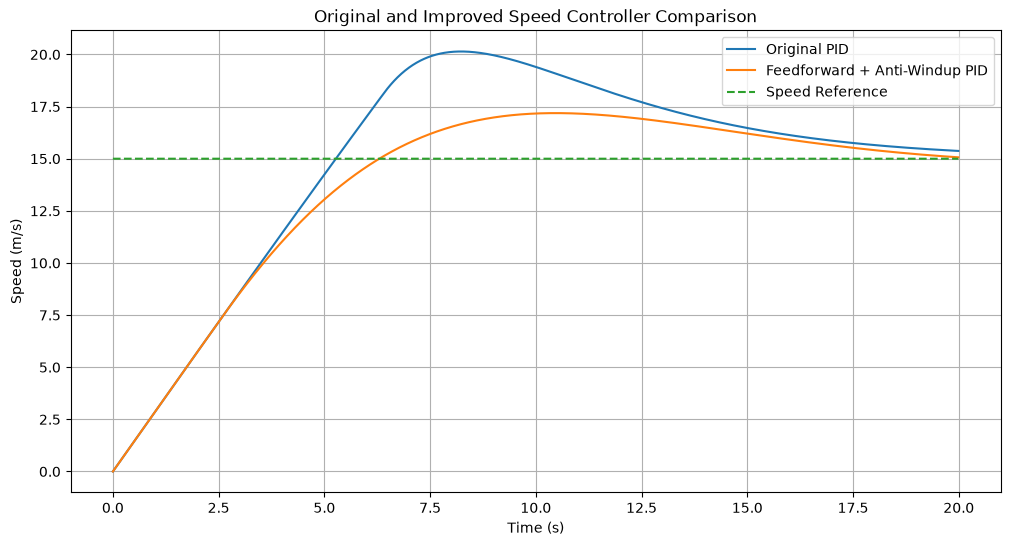

In [46]:
# 45-18D — Original and Improved Response Plot

plt.figure(figsize=(12, 6))

plt.plot(
    speed_time,
    vehicle_speed,
    label="Original PID"
)

plt.plot(
    speed_time,
    improved_speed,
    label="Feedforward + Anti-Windup PID"
)

plt.plot(
    speed_time,
    np.full_like(speed_time, speed_reference),
    linestyle="--",
    label="Speed Reference"
)

plt.xlabel("Time (s)")
plt.ylabel("Speed (m/s)")
plt.title("Original and Improved Speed Controller Comparison")
plt.grid(True)
plt.legend()
plt.show()

## Validation

The improved simulation is validated by checking:

- Expected array lengths.
- Finite speed and acceleration values.
- Non-negative vehicle speed.
- Valid performance metrics.

In [47]:
# 46-18D — Improved Controller Validation

assert len(improved_speed) == len(speed_time)
assert len(improved_acceleration) == len(speed_time)
assert len(improved_error) == len(speed_time)

assert np.all(np.isfinite(improved_speed))
assert np.all(np.isfinite(improved_acceleration))
assert np.all(np.isfinite(improved_error))

assert np.min(improved_speed) >= 0.0

assert np.isfinite(
    improved_metrics["MAE (m/s)"]
)

assert np.isfinite(
    improved_metrics["Final Absolute Error (m/s)"]
)

print("Improved vehicle speed controller validation completed successfully.")

Improved vehicle speed controller validation completed successfully.
